# Concurrency prediction based on actual and/or predicted schedules

In [1]:
# Import required libraries
import h2o
from h2o.automl import H2OAutoML
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import warnings

warnings.filterwarnings("ignore")

# Initialize H2O
print("Initializing H2O...")
h2o.init(max_mem_size="4G")  # Adjust based on available memory
print("H2O initialized successfully!")

Initializing H2O...
Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
  Java Version: openjdk version "21.0.8" 2025-07-15; OpenJDK Runtime Environment (build 21.0.8+9-Ubuntu-0ubuntu124.04.1); OpenJDK 64-Bit Server VM (build 21.0.8+9-Ubuntu-0ubuntu124.04.1, mixed mode, sharing)
  Starting server from /lhome/kristsey/AvinorHackathon/.venv/lib/python3.12/site-packages/h2o/backend/bin/h2o.jar
  Ice root: /tmp/tmp8dc4il7n
  JVM stdout: /tmp/tmp8dc4il7n/h2o_kristsey_started_from_python.out
  JVM stderr: /tmp/tmp8dc4il7n/h2o_kristsey_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.
Please download and install the latest version from: https://h2o-release.s3.amazonaws.com/h2o/latest_stable.html


H2O_cluster_uptime:,01 secs
H2O_cluster_timezone:,Europe/Oslo
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.7
H2O_cluster_version_age:,6 months and 2 days
H2O_cluster_name:,H2O_from_python_kristsey_1seink
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.981 Gb
H2O_cluster_total_cores:,32
H2O_cluster_allowed_cores:,32
H2O_cluster_status:,"locked, healthy"


H2O initialized successfully!


In [44]:
# Load the historical flights dataset
import os

print("Loading historical schedule data")
scheduled_path = os.path.abspath("../data/concurrency/scheduled_concurrency.csv")
actual_path = os.path.abspath("../data/concurrency/actual_concurrency.csv")
predicted_path = os.path.abspath("../data/concurrency/predicted_concurrency.csv")

# Combine chunks
df_scheduled = pd.read_csv(scheduled_path)  # Use predicted for testing
df_actual = pd.read_csv(actual_path)
df_predicted = pd.read_csv(predicted_path)
print(len(df_scheduled), len(df_actual), len(df_predicted))
print(df_scheduled["date"].min(), df_actual["date"].min(), df_predicted["date"].min())
print(df_scheduled["date"].max(), df_actual["date"].max(), df_predicted["date"].max())

# Display basic information about the dataset
print("\nDataset Info:")
print(df_scheduled.info())
print("\nFirst few rows:")
print(df_scheduled.head())
print("\nDataset statistics:")
print(df_scheduled.describe())

# Create the main dataframe from scheduled/predicted data and set target values to actual values
df = df_scheduled[["airport_group", "date", "hour"]].copy()
df[
    [
        "scheduled_concurrency",
        "scheduled_number_of_flights",
        "scheduled_overlapping_time_minutes",
        "scheduled_is_concurrency",
    ]
] = df_scheduled[
    ["concurrency", "number_of_flights", "overlapping_time_minutes", "is_concurrency"]
]
# df[
#     [
#         "predicted_concurrency",
#         "predicted_number_of_flights",
#         "predicted_overlapping_time_minutes",
#         "predicted_is_concurrency",
#     ]
# ] = df_predicted[
#     ["concurrency", "number_of_flights", "overlapping_time_minutes", "is_concurrency"]
# ]

df["is_concurrency"] = df_actual["is_concurrency"]  # set target values to actual values

print(f"\nTarget variable distribution:")
print(df["is_concurrency"].value_counts())
print(f"Target variable type: {df['is_concurrency'].dtype}")

Loading historical schedule data
465360 465360 465360
2018-01-01 2018-01-01 2018-01-01
2025-08-01 2025-08-01 2025-08-01

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 465360 entries, 0 to 465359
Data columns (total 7 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   airport_group             465360 non-null  object 
 1   date                      465360 non-null  object 
 2   hour                      465360 non-null  int64  
 3   concurrency               465360 non-null  int64  
 4   number_of_flights         465360 non-null  int64  
 5   overlapping_time_minutes  465360 non-null  float64
 6   is_concurrency            465360 non-null  int64  
dtypes: float64(1), int64(4), object(2)
memory usage: 24.9+ MB
None

First few rows:
  airport_group        date  hour  concurrency  number_of_flights  \
0             A  2018-01-01     0            0                  0   
1             B  2018-01-01 

In [45]:
schedule_25_path = os.path.abspath(
    "../data/concurrency/scheduled_concurrency_oct_25.csv"
)
df_scheduled_25 = pd.read_csv(schedule_25_path)

# Create the main dataframe from scheduled/predicted data and set target values to actual values
df_final = df_scheduled_25[["airport_group", "date", "hour"]].copy()
df_final[
    [
        "scheduled_concurrency",
        "scheduled_number_of_flights",
        "scheduled_overlapping_time_minutes",
        "scheduled_is_concurrency",
    ]
] = df_scheduled_25[
    ["concurrency", "number_of_flights", "overlapping_time_minutes", "is_concurrency"]
]

In [46]:
test_path_schedule = os.path.abspath(
    "../data/concurrency/scheduled_concurrency_october_24.csv"
)
test_path_predicted = os.path.abspath(
    "../data/concurrency/predicted_concurrency_october_24.csv"
)
test_path_actual = os.path.abspath(
    "../data/concurrency/actual_concurrency_october_24.csv"
)

df_schedule_test = pd.read_csv(test_path_schedule)  # retrieve test dataset for testing
df_predicted_test = pd.read_csv(
    test_path_predicted
)  # retrieve test dataset for testing
df_actual_test = pd.read_csv(test_path_actual)

print(len(df_schedule_test), len(df_predicted_test), len(df_actual_test))

# Create the main dataframe from scheduled/predicted data and set target values to actual values
df_test = df_schedule_test[["airport_group", "date", "hour"]].copy()
df_test[
    [
        "scheduled_concurrency",
        "scheduled_number_of_flights",
        "scheduled_overlapping_time_minutes",
        "scheduled_is_concurrency",
    ]
] = df_schedule_test[
    ["concurrency", "number_of_flights", "overlapping_time_minutes", "is_concurrency"]
]
df_test[
    [
        "predicted_concurrency",
        "predicted_number_of_flights",
        "predicted_overlapping_time_minutes",
        "predicted_is_concurrency",
    ]
] = df_predicted_test[
    ["concurrency", "number_of_flights", "overlapping_time_minutes", "is_concurrency"]
]

df_test["is_concurrency"] = df_actual_test[
    "is_concurrency"
]  # set target values to actual values

print(f"\nTarget variable distribution:")
print(df_test["is_concurrency"].value_counts())
print(f"Target variable type: {df_test['is_concurrency'].dtype}")

5376 5208 5208

Target variable distribution:
is_concurrency
0.0    3755
1.0    1453
Name: count, dtype: int64
Target variable type: float64


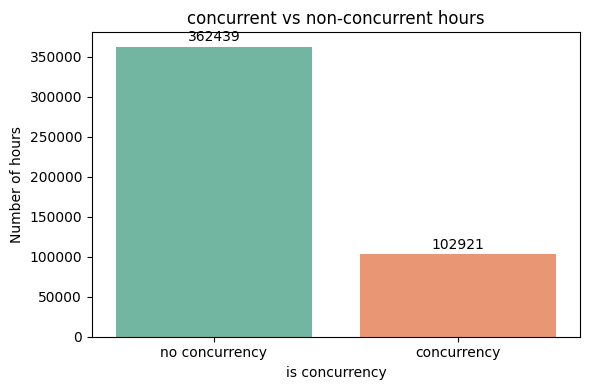

In [4]:
# Plot is_concurrency
import matplotlib.pyplot as plt
import seaborn as sns

# Convert 'cancelled' to boolean for plotting
cancel_bool = df["is_concurrency"].astype(bool)
cancel_counts = cancel_bool.value_counts().sort_index()
labels = ["no concurrency", "concurrency"]

plt.figure(figsize=(6, 4))
sns.barplot(x=labels, y=cancel_counts.values, palette="Set2")
plt.title("concurrent vs non-concurrent hours")
plt.ylabel("Number of hours")
plt.xlabel("is concurrency")
for i, v in enumerate(cancel_counts.values):
    plt.text(i, v + max(cancel_counts.values) * 0.01, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

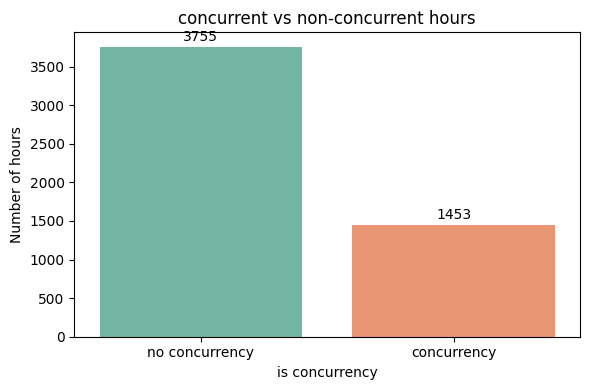

In [5]:
# Plot is_concurrency
import matplotlib.pyplot as plt
import seaborn as sns

# Convert 'cancelled' to boolean for plotting
cancel_bool = df_test["is_concurrency"].astype(bool)
cancel_counts = cancel_bool.value_counts().sort_index()
labels = ["no concurrency", "concurrency"]

plt.figure(figsize=(6, 4))
sns.barplot(x=labels, y=cancel_counts.values, palette="Set2")
plt.title("concurrent vs non-concurrent hours")
plt.ylabel("Number of hours")
plt.xlabel("is concurrency")
for i, v in enumerate(cancel_counts.values):
    plt.text(i, v + max(cancel_counts.values) * 0.01, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

In [6]:
df_processed = df.copy()
# Convert date and time columns to datetime
df_processed["date"] = pd.to_datetime(
    df_processed["date"] + " " + df_processed["hour"].astype(str) + ":00:00"
)
df_processed
# Extract time features from scheduled departure time
df_processed["dep_hour"] = df_processed["date"].dt.hour
df_processed["dep_day_of_week"] = df_processed["date"].dt.dayofweek
df_processed["dep_month"] = df_processed["date"].dt.month
df_processed["dep_day_of_year"] = df_processed["date"].dt.dayofyear

# Extract time features from scheduled arrival time
df_processed["arr_hour"] = df_processed["date"].dt.hour

# Circular encoding for time-based features
print("Creating circular encodings for time-based features...")

# Hour of day (0-23) - circular encoding
df_processed["hour_sin"] = np.sin(2 * np.pi * df_processed["dep_hour"] / 24)
df_processed["hour_cos"] = np.cos(2 * np.pi * df_processed["dep_hour"] / 24)

df_processed["day_of_week_sin"] = np.sin(
    2 * np.pi * df_processed["dep_day_of_week"] / 7
)
df_processed["day_of_week_cos"] = np.cos(
    2 * np.pi * df_processed["dep_day_of_week"] / 7
)

df_processed["month_sin"] = np.sin(2 * np.pi * df_processed["dep_month"] / 12)
df_processed["month_cos"] = np.cos(2 * np.pi * df_processed["dep_month"] / 12)

df_processed["day_of_year_sin"] = np.sin(
    2 * np.pi * df_processed["dep_day_of_year"] / 365
)
df_processed["day_of_year_cos"] = np.cos(
    2 * np.pi * df_processed["dep_day_of_year"] / 365
)

print("Circular encodings created successfully!")

df_processed["year"] = df_processed["date"].dt.year
df_processed["airport_group"] = df_processed["airport_group"].fillna("OUT")
df_processed["airport_group"] = df_processed["airport_group"].astype("category")
df_processed["is_concurrency"] = df_processed["is_concurrency"].astype("category")

Creating circular encodings for time-based features...
Circular encodings created successfully!


In [ ]:
df_processed_test = df_test.copy()
# Convert date and time columns to datetime
df_processed_test["date"] = pd.to_datetime(
    df_processed_test["date"] + " " + df_processed_test["hour"].astype(str) + ":00:00"
)
# Extract time features from scheduled departure time
df_processed_test["dep_hour"] = df_processed_test["date"].dt.hour
df_processed_test["dep_day_of_week"] = df_processed_test["date"].dt.dayofweek
df_processed_test["dep_month"] = df_processed_test["date"].dt.month
df_processed_test["dep_day_of_year"] = df_processed_test["date"].dt.dayofyear

# Extract time features from scheduled arrival time
df_processed_test["arr_hour"] = df_processed_test["date"].dt.hour

# Circular encoding for time-based features
print("Creating circular encodings for time-based features...")

# Hour of day (0-23) - circular encoding
df_processed_test["hour_sin"] = np.sin(2 * np.pi * df_processed_test["dep_hour"] / 24)
df_processed_test["hour_cos"] = np.cos(2 * np.pi * df_processed_test["dep_hour"] / 24)

df_processed_test["day_of_week_sin"] = np.sin(
    2 * np.pi * df_processed_test["dep_day_of_week"] / 7
)
df_processed_test["day_of_week_cos"] = np.cos(
    2 * np.pi * df_processed_test["dep_day_of_week"] / 7
)

df_processed_test["month_sin"] = np.sin(2 * np.pi * df_processed_test["dep_month"] / 12)
df_processed_test["month_cos"] = np.cos(2 * np.pi * df_processed_test["dep_month"] / 12)

df_processed_test["day_of_year_sin"] = np.sin(
    2 * np.pi * df_processed_test["dep_day_of_year"] / 365
)
df_processed_test["day_of_year_cos"] = np.cos(
    2 * np.pi * df_processed_test["dep_day_of_year"] / 365
)

print("Circular encodings created successfully!")

df_processed_test["year"] = df_processed_test["date"].dt.year
df_processed_test["airport_group"] = df_processed_test["airport_group"].fillna("OUT")
df_processed_test["airport_group"] = df_processed_test["airport_group"].astype(
    "category"
)
df_processed_test["is_concurrency"] = df_processed_test["is_concurrency"].astype(
    "category"
)

Creating circular encodings for time-based features...
Circular encodings created successfully!


In [ ]:
feature_columns = [
    "airport_group",
    "year",
    "hour_sin",
    "hour_cos",
    "day_of_week_sin",
    "day_of_week_cos",
    "month_sin",
    "month_cos",
    "day_of_year_sin",
    "day_of_year_cos",
    "scheduled_concurrency",
    "scheduled_number_of_flights",
    "scheduled_overlapping_time_minutes",
    "scheduled_is_concurrency",
    # "predicted_concurrency", #Removed for testing
    # "predicted_number_of_flights",
    # "predicted_overlapping_time_minutes",
    # "predicted_is_concurrency",
    "date",
]

print(f"Total features selected: {len(feature_columns)}")


model_data = df_processed[feature_columns + ["is_concurrency"]].copy()
model_data_test = df_processed_test[feature_columns + ["is_concurrency"]].copy()

# Remove rows with missing values in key features
print(f"Modeling dataset shape: {model_data.shape}")

Total features selected: 15
Modeling dataset shape: (465360, 16)


In [9]:
train_df = model_data.copy()
test_df = model_data_test.copy()


# Verify no overlaps between sets
print(f"Train set shape: {train_df.shape}")
print(f"Test set shape: {test_df.shape}")


# Convert to H2O frames
test = h2o.H2OFrame(test_df.drop(["date"], axis=1))
train = h2o.H2OFrame(train_df.drop(["date"], axis=1))

Train set shape: (465360, 16)
Test set shape: (5208, 16)
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


In [10]:
# Convert categorical columns back to factors
test["is_concurrency"] = test["is_concurrency"].asfactor()
test["airport_group"] = test["airport_group"].asfactor()
train["is_concurrency"] = train["is_concurrency"].asfactor()
train["airport_group"] = train["airport_group"].asfactor()

print(f"Train set shape: {train.shape}")
print(f"Test set shape: {test.shape}")

# Define predictors and response (excluding date from features)
x = [col for col in feature_columns if col != "date"]
y = "is_concurrency"

print(f"Features (x): {x}")
print(f"Target (y): {y}")

# Verify target is categorical
print(f"Target variable type: {train[y].types}")

# Check class balance in training set
train_target_summary = train[y].table()
print(f"\nClass distribution in training set:")
print(train_target_summary)

# Initialize H2O AutoML with corrected settings for binary classification
print("\nInitializing H2O AutoML for binary classification...")
aml = H2OAutoML(
    max_models=12,
    max_runtime_secs=600,  # 10 minutes
    balance_classes=True,  # Handle class imbalance
    seed=42,
    project_name="concurrency_prediction",
    sort_metric="AUC",  # Now correct for binary classification
    include_algos=[
        "GLM",
        "GBM",
        "XGBoost",
        "DRF",
        "DeepLearning",
    ],  # StackedEnsemble , removed for feature importance
    nfolds=-1,
    stopping_metric="AUC",
    stopping_tolerance=0.01,
    stopping_rounds=3,
    max_after_balance_size=3.0,
)

# Train AutoML models
print("Training AutoML models for binary classification...")
print("This should work now - estimated 3-5 minutes...")
aml.train(x=x, y=y, training_frame=train)

print("\nAutoML training completed!")
print(f"Leaderboard contains {len(aml.leaderboard)} models")

Train set shape: (465360, 15)
Test set shape: (5208, 15)
Features (x): ['airport_group', 'year', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'day_of_year_sin', 'day_of_year_cos', 'scheduled_concurrency', 'scheduled_number_of_flights', 'scheduled_overlapping_time_minutes', 'scheduled_is_concurrency']
Target (y): is_concurrency
Target variable type: {'is_concurrency': 'enum'}

Class distribution in training set:
  is_concurrency    Count
               0   362439
               1   102921
[2 rows x 2 columns]


Initializing H2O AutoML for binary classification...
Training AutoML models for binary classification...
This should work now - estimated 3-5 minutes...
AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%

AutoML training completed!
Leaderboard contains 12 models


In [11]:
# View the leaderboard
print("AutoML Leaderboard:")
leaderboard = aml.leaderboard.as_data_frame()
print(leaderboard)

# Get the best model
best_model = aml.leader
print(f"\nBest model: {best_model.model_id}")

# Evaluate on test set
print("\nEvaluating best model on test set...")
test_performance = best_model.model_performance(test)

# Extract metrics properly - H2O returns different formats
try:
    # Try different ways to extract AUC
    auc_value = test_performance.auc()
    if isinstance(auc_value, list) and len(auc_value) > 0:
        auc_value = auc_value[0][0] if isinstance(auc_value[0], list) else auc_value[0]
    print(f"Test AUC: {auc_value:.4f}")
except:
    print("Could not extract AUC")

try:
    # Extract accuracy at different thresholds
    accuracy_data = test_performance.accuracy()
    if isinstance(accuracy_data, list) and len(accuracy_data) > 0:
        # Usually accuracy is reported at optimal threshold
        accuracy_value = (
            accuracy_data[0][1] if len(accuracy_data[0]) > 1 else accuracy_data[0]
        )
        print(f"Test Accuracy: {accuracy_value:.4f}")
    else:
        print(f"Test Accuracy: {accuracy_data:.4f}")
except:
    print("Could not extract Accuracy")

try:
    # Extract precision and recall
    precision_data = test_performance.precision()
    recall_data = test_performance.recall()

    if isinstance(precision_data, list) and len(precision_data) > 0:
        precision_value = (
            precision_data[0][1] if len(precision_data[0]) > 1 else precision_data[0]
        )
        print(f"Test Precision: {precision_value:.4f}")

    if isinstance(recall_data, list) and len(recall_data) > 0:
        recall_value = recall_data[0][1] if len(recall_data[0]) > 1 else recall_data[0]
        print(f"Test Recall: {recall_value:.4f}")

    # Calculate F1 Score from precision and recall
    if "precision_value" in locals() and "recall_value" in locals():
        if precision_value > 0 and recall_value > 0:
            f1_score = (
                2 * (precision_value * recall_value) / (precision_value + recall_value)
            )
            print(f"Test F1-Score: {f1_score:.4f}")
        else:
            print("Test F1-Score: 0.0000 (precision or recall is zero)")
    else:
        print("Could not calculate F1-Score")

except:
    print("Could not extract Precision/Recall")

# Print confusion matrix
print("\nConfusion Matrix:")
try:
    cm = test_performance.confusion_matrix()
    print(cm)
except:
    print("Could not generate confusion matrix")

# Generate predictions on test set
print("\nGenerating predictions on test set...")
predictions = best_model.predict(test)
print("Sample predictions:")
print(predictions.head())

# Feature importance (if available)
try:
    print("\nFeature Importance:")
    importance = best_model.varimp(use_pandas=True)
    print(importance.head(10))
except:
    print("Feature importance not available for this model type")

# Print overall model performance summary
print("\nOverall Model Performance Summary:")
print(test_performance)

AutoML Leaderboard:
                                  model_id       auc   logloss     aucpr  \
0            GBM_1_AutoML_1_20250930_82539  0.979262  0.162562  0.932708   
1        XGBoost_1_AutoML_1_20250930_82539  0.977960  0.185082  0.929062   
2            GBM_4_AutoML_1_20250930_82539  0.977496  0.169322  0.928703   
3        XGBoost_2_AutoML_1_20250930_82539  0.977411  0.193060  0.927969   
4            DRF_1_AutoML_1_20250930_82539  0.976684  0.184398  0.924542   
5            XRT_1_AutoML_1_20250930_82539  0.976170  0.168439  0.924598   
6            GBM_3_AutoML_1_20250930_82539  0.975271  0.176682  0.923007   
7            GBM_2_AutoML_1_20250930_82539  0.973780  0.181330  0.920017   
8            GBM_5_AutoML_1_20250930_82539  0.971581  0.186860  0.915698   
9        XGBoost_3_AutoML_1_20250930_82539  0.971461  0.219664  0.915299   
10  DeepLearning_1_AutoML_1_20250930_82539  0.969812  0.181410  0.908358   
11           GLM_1_AutoML_1_20250930_82539  0.958953  0.203878  0.89

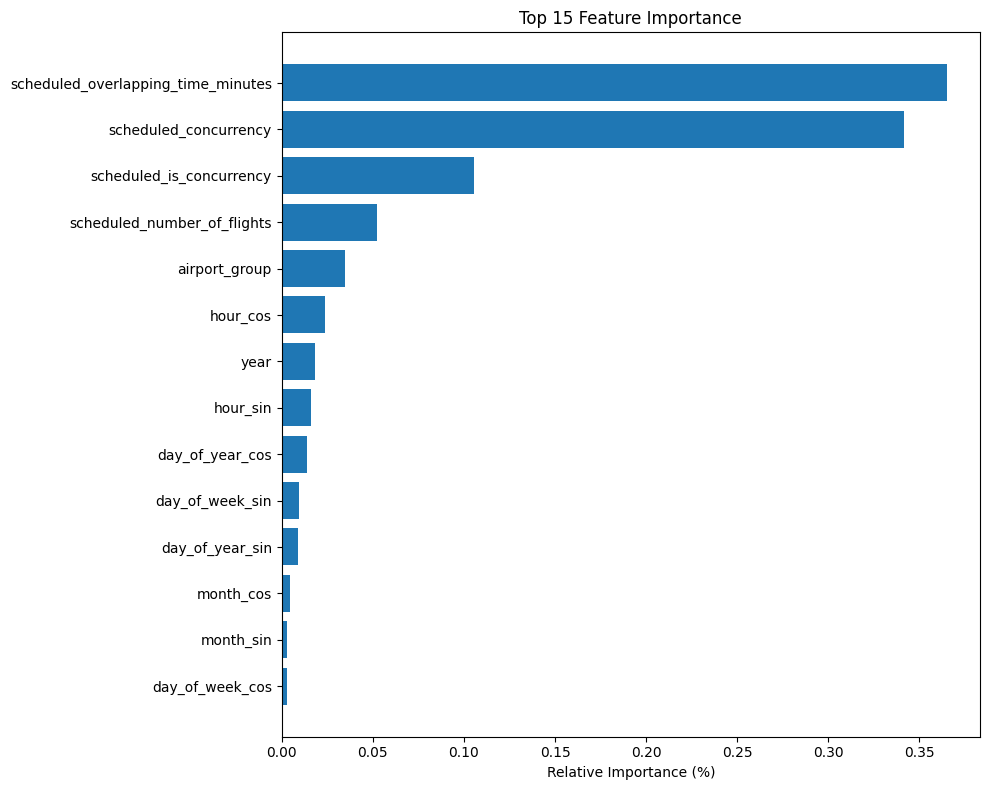

In [13]:
# Plot variable importance
varim = best_model.varimp(use_pandas=True)
plt.figure(figsize=(10, 8))
if len(varim) > 0:
    top_features = varim.head(15)
    plt.barh(range(len(top_features)), top_features["percentage"])
    plt.yticks(range(len(top_features)), top_features["variable"])
    plt.xlabel("Relative Importance (%)")
    plt.title("Top 15 Feature Importance")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("No variable importance data available")

In [21]:
h2o.save_model(
    best_model,
    "../models/concurrency_model",
    filename="best",
    force=True,
)

'/lhome/kristsey/AvinorHackathon/models/concurrency_model/best'

In [ ]:
train_df_final = pd.concat([train_df, test_df])

# Verify no overlaps between sets
print(f"Final Train set shape: {train_df_final.shape}")


train_final = h2o.H2OFrame(train_df_final.drop(["date"], axis=1))

Final Train set shape: (470568, 16)
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


In [ ]:
train_final["is_concurrency"] = train_final["is_concurrency"].asfactor()
train_final["airport_group"] = train_final["airport_group"].asfactor()

print(f"Train set shape: {train_final.shape}")

# Define predictors and response (excluding date from features)
x = [col for col in feature_columns if col != "date"]
y = "is_concurrency"

print(f"Features (x): {x}")
print(f"Target (y): {y}")

# Verify target is categorical
print(f"Target variable type: {train_final[y].types}")

# Check class balance in training set
train_target_summary = train_final[y].table()
print(f"\nClass distribution in training set:")
print(train_target_summary)

# Initialize H2O AutoML with corrected settings for binary classification
print("\nInitializing H2O AutoML for binary classification...")
aml = H2OAutoML(
    max_models=12,
    max_runtime_secs=600,  # 10 minutes
    balance_classes=True,  # Handle class imbalance
    seed=42,
    project_name="concurrency_prediction",
    sort_metric="AUC",  # Now correct for binary classification
    include_algos=[
        "GLM",
        "GBM",
        "XGBoost",
        "DRF",
        "DeepLearning",
    ],  # StackedEnsemble , removed for feature importance
    nfolds=-1,
    stopping_metric="AUC",
    stopping_tolerance=0.01,
    stopping_rounds=3,
    max_after_balance_size=3.0,
)

# Train AutoML models
print("Training AutoML models for binary classification...")
print("This should work now - estimated 3-5 minutes...")
aml.train(x=x, y=y, training_frame=train_final)

print("\nAutoML training completed!")
print(f"Leaderboard contains {len(aml.leaderboard)} models")

Train set shape: (470568, 15)
Features (x): ['airport_group', 'year', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'day_of_year_sin', 'day_of_year_cos', 'scheduled_concurrency', 'scheduled_number_of_flights', 'scheduled_overlapping_time_minutes', 'scheduled_is_concurrency']
Target (y): is_concurrency
Target variable type: {'is_concurrency': 'enum'}

Class distribution in training set:
  is_concurrency    Count
               0   366194
               1   104374
[2 rows x 2 columns]


Initializing H2O AutoML for binary classification...
Training AutoML models for binary classification...
This should work now - estimated 3-5 minutes...
AutoML progress: |
08:57:05.663: New models will be added to existing leaderboard concurrency_prediction@@is_concurrency (leaderboard frame=null) with already 12 models.

███████████████████████████████████████████████████████████████| (done) 100%

AutoML training completed!
Leaderboard contains 24 models


In [26]:
final_best_model = aml.leader
h2o.save_model(
    final_best_model,
    "../models/concurrency_model_final",
    filename="best",
    force=True,
)

'/lhome/kristsey/AvinorHackathon/models/concurrency_model_final/best'

In [29]:
final_predictions = final_best_model.predict(
    h2o.H2OFrame(df_final.drop(["date"], axis=1))
)

Parse progress: |

████████████████████████████████████████████████████████████████| (done) 100%
gbm prediction progress: |███████████████████████████████████████████████████████| (done) 100%


In [41]:
october_25_predictions = df_final.copy()[
    [
        "airport_group",
        "date",
        "hour",
    ]
]

df_final_predictions = final_predictions.as_data_frame()
october_25_predictions["concurrency"] = df_final_predictions["p1"].round(3)
print(october_25_predictions.head())

october_25_predictions.to_csv(
    "../data/predictions/final_predictions_october_25.csv", index=False
)

  airport_group        date  hour  concurrency
0             A  2025-10-01     0        0.015
1             B  2025-10-01     0        0.014
2             C  2025-10-01     0        0.007
3             D  2025-10-01     0        0.012
4             E  2025-10-01     0        0.014


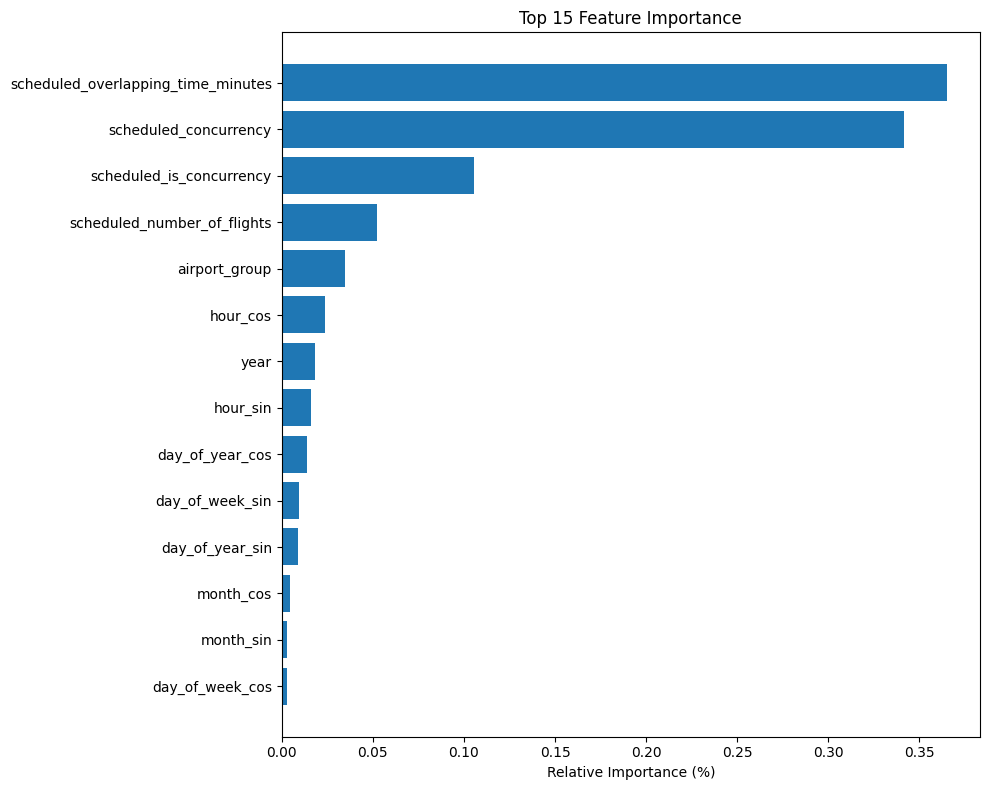

In [27]:
# Plot variable importance
varim = final_best_model.varimp(use_pandas=True)
plt.figure(figsize=(10, 8))
if len(varim) > 0:
    top_features = varim.head(15)
    plt.barh(range(len(top_features)), top_features["percentage"])
    plt.yticks(range(len(top_features)), top_features["variable"])
    plt.xlabel("Relative Importance (%)")
    plt.title("Top 15 Feature Importance")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("No variable importance data available")

In [28]:
# View the leaderboard
print("AutoML Leaderboard:")
leaderboard = aml.leaderboard.as_data_frame()
print(leaderboard)

# Get the best model
best_model = aml.leader
print(f"\nBest model: {best_model.model_id}")

# Evaluate on test set
print("\nEvaluating best model on test set...")
test_performance = best_model.model_performance(test)

# Extract metrics properly - H2O returns different formats
try:
    # Try different ways to extract AUC
    auc_value = test_performance.auc()
    if isinstance(auc_value, list) and len(auc_value) > 0:
        auc_value = auc_value[0][0] if isinstance(auc_value[0], list) else auc_value[0]
    print(f"Test AUC: {auc_value:.4f}")
except:
    print("Could not extract AUC")

try:
    # Extract accuracy at different thresholds
    accuracy_data = test_performance.accuracy()
    if isinstance(accuracy_data, list) and len(accuracy_data) > 0:
        # Usually accuracy is reported at optimal threshold
        accuracy_value = (
            accuracy_data[0][1] if len(accuracy_data[0]) > 1 else accuracy_data[0]
        )
        print(f"Test Accuracy: {accuracy_value:.4f}")
    else:
        print(f"Test Accuracy: {accuracy_data:.4f}")
except:
    print("Could not extract Accuracy")

try:
    # Extract precision and recall
    precision_data = test_performance.precision()
    recall_data = test_performance.recall()

    if isinstance(precision_data, list) and len(precision_data) > 0:
        precision_value = (
            precision_data[0][1] if len(precision_data[0]) > 1 else precision_data[0]
        )
        print(f"Test Precision: {precision_value:.4f}")

    if isinstance(recall_data, list) and len(recall_data) > 0:
        recall_value = recall_data[0][1] if len(recall_data[0]) > 1 else recall_data[0]
        print(f"Test Recall: {recall_value:.4f}")

    # Calculate F1 Score from precision and recall
    if "precision_value" in locals() and "recall_value" in locals():
        if precision_value > 0 and recall_value > 0:
            f1_score = (
                2 * (precision_value * recall_value) / (precision_value + recall_value)
            )
            print(f"Test F1-Score: {f1_score:.4f}")
        else:
            print("Test F1-Score: 0.0000 (precision or recall is zero)")
    else:
        print("Could not calculate F1-Score")

except:
    print("Could not extract Precision/Recall")

# Print confusion matrix
print("\nConfusion Matrix:")
try:
    cm = test_performance.confusion_matrix()
    print(cm)
except:
    print("Could not generate confusion matrix")

# Generate predictions on test set
print("\nGenerating predictions on test set...")
predictions = best_model.predict(test)
print("Sample predictions:")
print(predictions.head())

# Feature importance (if available)
try:
    print("\nFeature Importance:")
    importance = best_model.varimp(use_pandas=True)
    print(importance.head(10))
except:
    print("Feature importance not available for this model type")

# Print overall model performance summary
print("\nOverall Model Performance Summary:")
print(test_performance)

AutoML Leaderboard:
                                  model_id       auc   logloss     aucpr  \
0            GBM_1_AutoML_1_20250930_82539  0.979262  0.162562  0.932708   
1            GBM_6_AutoML_2_20250930_85705  0.979212  0.162880  0.932791   
2        XGBoost_1_AutoML_1_20250930_82539  0.977960  0.185082  0.929062   
3        XGBoost_4_AutoML_2_20250930_85705  0.977760  0.185600  0.928823   
4            GBM_4_AutoML_1_20250930_82539  0.977496  0.169322  0.928703   
5            GBM_9_AutoML_2_20250930_85705  0.977452  0.169716  0.928740   
6        XGBoost_2_AutoML_1_20250930_82539  0.977411  0.193060  0.927969   
7        XGBoost_5_AutoML_2_20250930_85705  0.977209  0.193757  0.928012   
8            DRF_1_AutoML_1_20250930_82539  0.976684  0.184398  0.924542   
9            DRF_2_AutoML_2_20250930_85705  0.976583  0.185802  0.924844   
10           XRT_2_AutoML_2_20250930_85705  0.976270  0.168180  0.925344   
11           XRT_1_AutoML_1_20250930_82539  0.976170  0.168439  0.92